In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score,precision_score,recall_score,roc_auc_score)

In [70]:
data= load_breast_cancer()

In [71]:
X= data.data[:,[0,1]]
Y=data.target

In [72]:
X_train,X_test,Y_train,Y_test= train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

In [73]:
scaler= StandardScaler()

In [74]:
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [75]:
linear_model = SVC(
    kernel='linear',
    probability=True,
    random_state=42
)
linear_model.fit(
    X_train,
    Y_train
)
linear_pred= linear_model.predict(
    X_test
)
linear_probability= linear_model.predict_proba(
    X_test
)[:,1]

print('===========')
print('Linear SVM')
print('===========')
print('accuracy: ',accuracy_score(Y_test,linear_pred))
print('Recall:',recall_score(Y_test,linear_pred))
print("AUC:", roc_auc_score(
    Y_test,
    linear_probability
)
     )

Linear SVM
accuracy:  0.868421052631579
Recall: 0.9027777777777778
AUC: 0.9527116402116402


In [76]:
rbf_model=SVC(
    kernel='rbf',
    probability= True,
    random_state=42
)
rbf_model.fit(
    X_train,
    Y_train
)
rbf_pred = rbf_model.predict(
    X_test
)
rbf_probability= rbf_model.predict_proba(
    X_test
)[:,1]
print('========')
print('RBF SVM ')
print('========')
print('accuracy:',
      accuracy_score(Y_test,rbf_pred)
     )
print('precision:',
      precision_score(Y_test,rbf_pred)
     )
print('Recall:',
      recall_score(Y_test,rbf_pred)
     )
print('AUC:',
      roc_auc_score(Y_test,rbf_probability)
     )

RBF SVM 
accuracy: 0.9035087719298246
precision: 0.9295774647887324
Recall: 0.9166666666666666
AUC: 0.9470899470899472


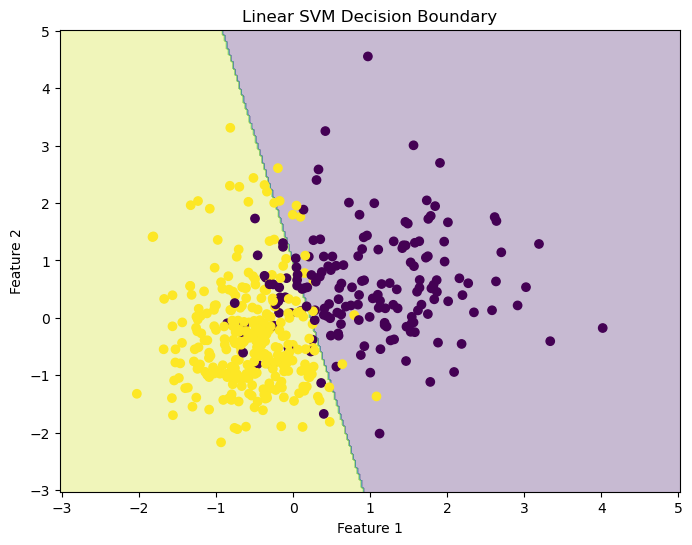

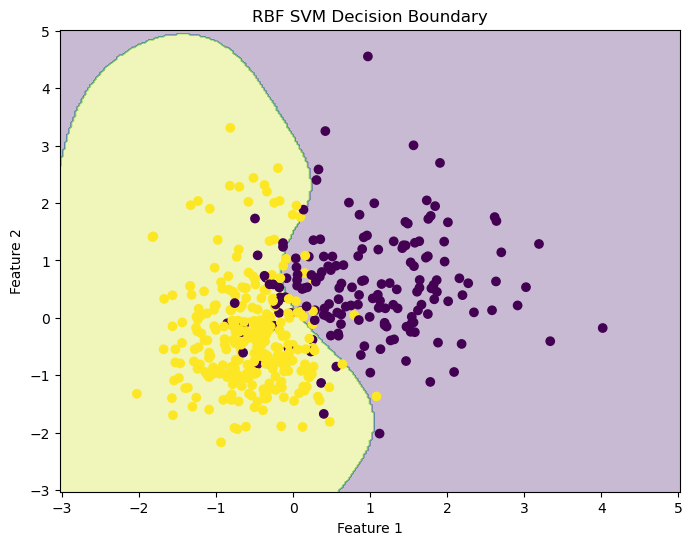

In [77]:
def plot_decision_boundary(model,X,Y,title):
    X_min = X[:,0].min()-1
    X_max = X[:,0].max()+1
    
    Y_min = X[:,0].min()-1
    Y_max = X[:,0].max()+1
    XX,YY= np.meshgrid(np.linspace(X_min,X_max,300),
                       np.linspace(Y_min,Y_max,300)
                      )
    points= np.c_[
    XX.ravel(),
    YY.ravel()
    ]
    predictions= model.predict(points)
    preditions=predictions.reshape(XX.shape)
    plt.figure(figsize=(8,6))
    plt.contourf(
        XX,
        YY,
        preditions,alpha=0.3
    )
    plt.scatter(
        X[:,0],
        X[:,1],
        c=Y
    )
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.title(title)
    plt.show()
plot_decision_boundary(
    linear_model,
    X_train,
    Y_train,
    'Linear SVM Decision Boundary'
)
plot_decision_boundary(
    rbf_model,
    X_train,
    Y_train,
    'RBF SVM Decision Boundary'
)
    
    